In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns

In [3]:
%matplotlib inline 
style.use("fivethirtyeight")
sns.set(style="whitegrid",color_codes=True)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score,precision_score,recall_score,roc,roc_curve,roc_auc_score

In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder

In [6]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [7]:
from keras import backend as K 
from keras.models import Sequential

In [8]:
from keras.layers import Dense
from keras.optimizers import Adam ,SGD,Adagrad,Adadelta,RMSprop

In [9]:
from keras.layers import Dropout,Flatten,Activation
from keras.layers import Conv2D,MaxPooling2D,BatchNormalization

In [10]:
import tensorflow as tf
import random as rn 

In [11]:
import cv2
import numpy as np
from tqdm import tqdm
import os
from  random import shuffle
from zipfile import ZipFile
from PIL import Image

In [12]:

IMG_SIZE=150
FLOWER_DAISY_DIR=r"C:\Users\Amala\Downloads\archive (3)\flowers\daisy"
FLOWER_SUNFLOWER_DIR=r"C:\Users\Amala\Downloads\archive (3)\flowers\sunflower"
FLOWER_ROSE_DIR=r"C:\Users\Amala\Downloads\archive (3)\flowers\rose"
FLOWER_TULIP_DIR=r"C:\Users\Amala\Downloads\archive (3)\flowers\tulip"
FLOWER_DANDILON_DIR=r"C:\Users\Amala\Downloads\archive (3)\flowers\dandelion"
x=[]
z=[]

In [13]:
def assign_label(img,flower_type):
    return flower_type

In [14]:
def make_train_data(flower_type,DIR):
    

    for img in tqdm(os.listdir(DIR)):
        label=assign_label(img,flower_type)
        path=os.path.join(DIR,img)
        img=cv2.imread(path,cv2.IMREAD_COLOR)
        if img is not None:
            img=cv2.resize(img,(IMG_SIZE,IMG_SIZE))
            x.append(np.array(img))
            z.append(flower_type)     

In [15]:
make_train_data("Daisy",FLOWER_DAISY_DIR)
print(len(x))

100%|███████████████████████████████████████████████████████████████████████████████| 764/764 [00:01<00:00, 621.68it/s]

764


In [16]:
make_train_data("Sunflower",FLOWER_SUNFLOWER_DIR)
print(len(x))

100%|███████████████████████████████████████████████████████████████████████████████| 733/733 [00:01<00:00, 520.29it/s]

1497


In [17]:
make_train_data("Tulip",FLOWER_TULIP_DIR)
print(len(x))

100%|███████████████████████████████████████████████████████████████████████████████| 984/984 [00:01<00:00, 650.51it/s]

2481


In [18]:
make_train_data("Rose",FLOWER_ROSE_DIR)
print(len(x))

100%|███████████████████████████████████████████████████████████████████████████████| 784/784 [00:01<00:00, 699.56it/s]


3265


In [19]:
make_train_data("Dandilon",FLOWER_DANDILON_DIR)
print(len(x))

100%|█████████████████████████████████████████████████████████████████████████████| 1052/1052 [00:01<00:00, 610.58it/s]

4317


In [20]:
flower_dirs = {
    "Daisy": FLOWER_DAISY_DIR,
    "Sunflower": FLOWER_SUNFLOWER_DIR,
    "Rose": FLOWER_ROSE_DIR,
    "Tulip": FLOWER_TULIP_DIR,
    "Dandelion": FLOWER_DANDILON_DIR
}

x, z = [], []

for flower, directory in flower_dirs.items():
    make_train_data(flower, directory)


100%|████████████████████████████████████████████████████████████████████████████| 1052/1052 [00:00<00:00, 1262.82it/s]


In [21]:
from collections import Counter
print(Counter(z))


Counter({'Dandelion': 1052, 'Tulip': 984, 'Rose': 784, 'Daisy': 764, 'Sunflower': 733})


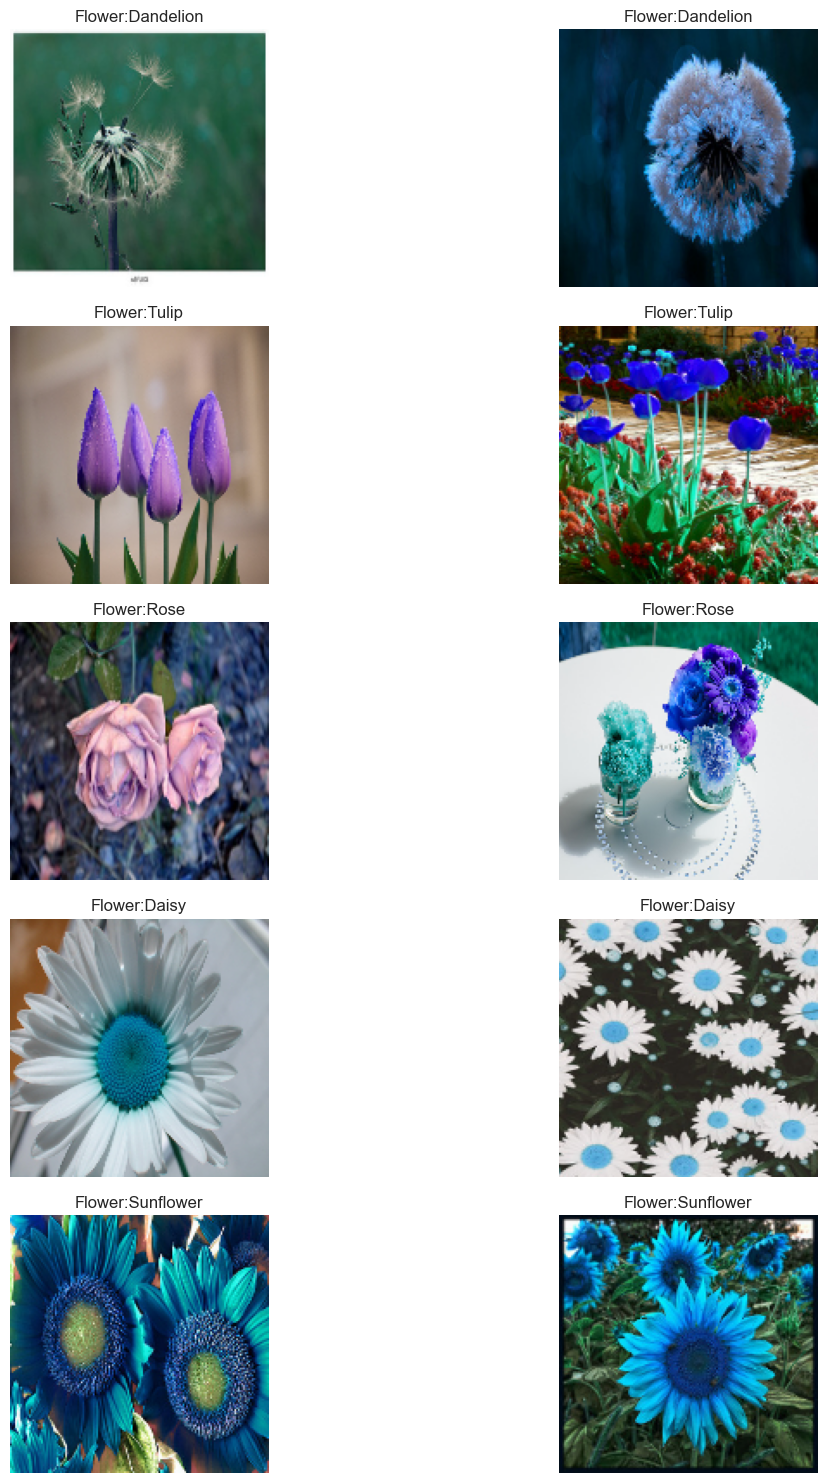

In [22]:
flower_types=['Dandelion','Tulip','Rose','Daisy','Sunflower']
fig,ax=plt.subplots(len(flower_types),2)
fig.set_size_inches(15,15)
for i,flower in enumerate(flower_types):
    indices=[k for k,lbl in enumerate(z) if lbl==flower]
    chosen=rn.sample(indices,2)
    for j,idx in enumerate(chosen):
        ax[i,j].imshow(x[idx])
        ax[i,j].set_title("Flower:"+z[idx])
        ax[i, j].axis("off")
plt.tight_layout()
plt.show()
        

In [23]:
le=LabelEncoder()

In [24]:
from keras.utils import to_categorical


In [25]:
y=le.fit_transform(z)
y=to_categorical(y,5)
x=np.array(x)
x=x/255

In [26]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.5,random_state=42)

In [27]:
np.random.seed(42)
rn.seed(42)
tf.random.set_seed(42)


In [28]:
model= Sequential()
model.add(Conv2D(filters=32,kernel_size=(5,5),padding="same",activation="relu",input_shape=(150,150,3)))
model.add(MaxPooling2D(pool_size=(2,2)))

In [29]:
model.add(Conv2D(filters=64,kernel_size=(3,3),padding="same",activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2),strides=(2,2)))

In [30]:
model.add(Conv2D(filters=96,kernel_size=(3,3),padding="same",activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2),strides=(2,2)))

In [31]:
model.add(Conv2D(filters=96,kernel_size=(3,3),padding="same",activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2),strides=(2,2)))

In [32]:
model.add(Flatten())
model.add(Dense(512))
model.add(Activation("relu"))
model.add(Dense(5,activation="softmax"))

In [33]:
batch_size=128
epochs=50
from keras.callbacks import ReduceLROnPlateau
red_lr=ReduceLROnPlateau(monitor="val_acc",patience=3,verbose=1,factor=0.1)

In [34]:
datagen=ImageDataGenerator(featurewise_center=False,samplewise_center=False,samplewise_std_normalization=False,featurewise_std_normalization=False,zca_whitening=False,rotation_range=10,zoom_range=0.1,width_shift_range=0.2,height_shift_range=0.2,horizontal_flip=True,vertical_flip=False)

In [35]:
datagen.fit(x_train)

In [36]:
model.compile(optimizer=Adam(learning_rate=0.001),loss="categorical_crossentropy",metrics=["accuracy"])

In [38]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 150, 150, 32)        │           2,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 75, 75, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 75, 75, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 37, 37, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 37, 37, 96)          │          55,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 18, 18, 96)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 18, 18, 96)          │          83,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 9, 9, 96)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 7776)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       3,981,824 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │           2,565 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,143,749 (15.81 MB)

 Trainable params: 4,143,749 (15.81 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
history=model.fit(datagen.flow(x_train,y_train,batch_size=batch_size),epochs=epochs,validation_data=(x_test,y_test),verbose=1,steps_per_epoch=x_train.shape[0]//batch_size)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.3404 - loss: 1.4718 - val_accuracy: 0.4497 - val_loss: 1.2607
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step - accuracy: 0.4453 - loss: 1.2371 - val_accuracy: 0.4187 - val_loss: 1.2766
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.4296 - loss: 1.2649 - val_accuracy: 0.5169 - val_loss: 1.1972
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 195ms/step - accuracy: 0.4844 - loss: 1.1354 - val_accuracy: 0.4947 - val_loss: 1.1863
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.5108 - loss: 1.1534 - val_accuracy: 0.5651 - val_loss: 1.0715
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 217ms/step - accuracy: 0.4531 - loss: 1.1810 - val_accuracy: 0.5317 - val_loss: 1.1364
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.5463 - loss: 1.0978 - val_accuracy: 0.5711 - val_loss: 1.1194
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 211ms/step - accuracy: 0.5000 - loss: 1.0985 - val_accuracy: 0.5887 - v

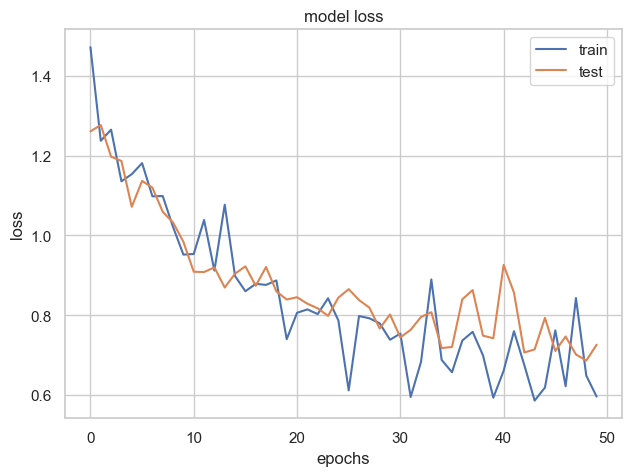

In [41]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epochs")
plt.legend(["train","test"])
plt.show()

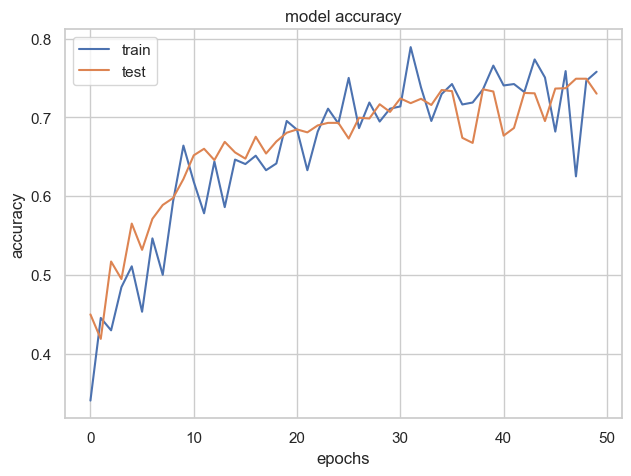

In [44]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("model accuracy")
plt.ylabel("accuracy")
plt.xlabel("epochs")
plt.legend(["train","test"])
plt.show()

In [45]:
pred=model.predict(x_test)

68/68 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step


In [46]:
pred_digits=np.argmax(pred,axis=1)

In [48]:
i=0
prop_class=[]
mis_class=[]
for i in range(len(y_test)):
    if(np.argmax(y_test[i])==pred_digits[i]):
        prop_class.append(i)
    if(len(prop_class)==8):
        break
i=0
for i in range (len(y_test)):
    if(not np.argmax(y_test[i])==pred_digits[i]):
        mis_class.append(i)
    if(len(mis_class)==8):
        break

In [54]:
pred_label=le.inverse_transform([pred_digits[prop_class[count]]])[0]
actual_label=le.inverse_transform([np.argmax(y_test[prop_class[count]])])[0]

In [57]:
unique_classes=np.unique(y_test.argmax(axis=1))

In [2]:
count = 0
fig, ax = plt.subplots(4, 2)
fig.set_size_inches(15, 15)

for i in range(4):
    for j in range(2):
        if count < len(unique_classes):
            cls = unique_classes[count]
            idx = np.random.choice(np.where(y_test.argmax(axis=1) == cls)[0])

            preds_label = le.inverse_transform([pred_digits[idx]])[0]
            actuals_label = le.inverse_transform([np.argmax(y_test[idx])])[0]

            ax[i, j].imshow(x_test[idx])
            ax[i, j].set_title(f"Predicted_Flower: {preds_label}\nActual_Flower: {actuals_label}")
            count += 1
        else:
            ax[i, j].axis("off")

plt.tight_layout()


NameError: name 'plt' is not defined

total misclassified samples:583


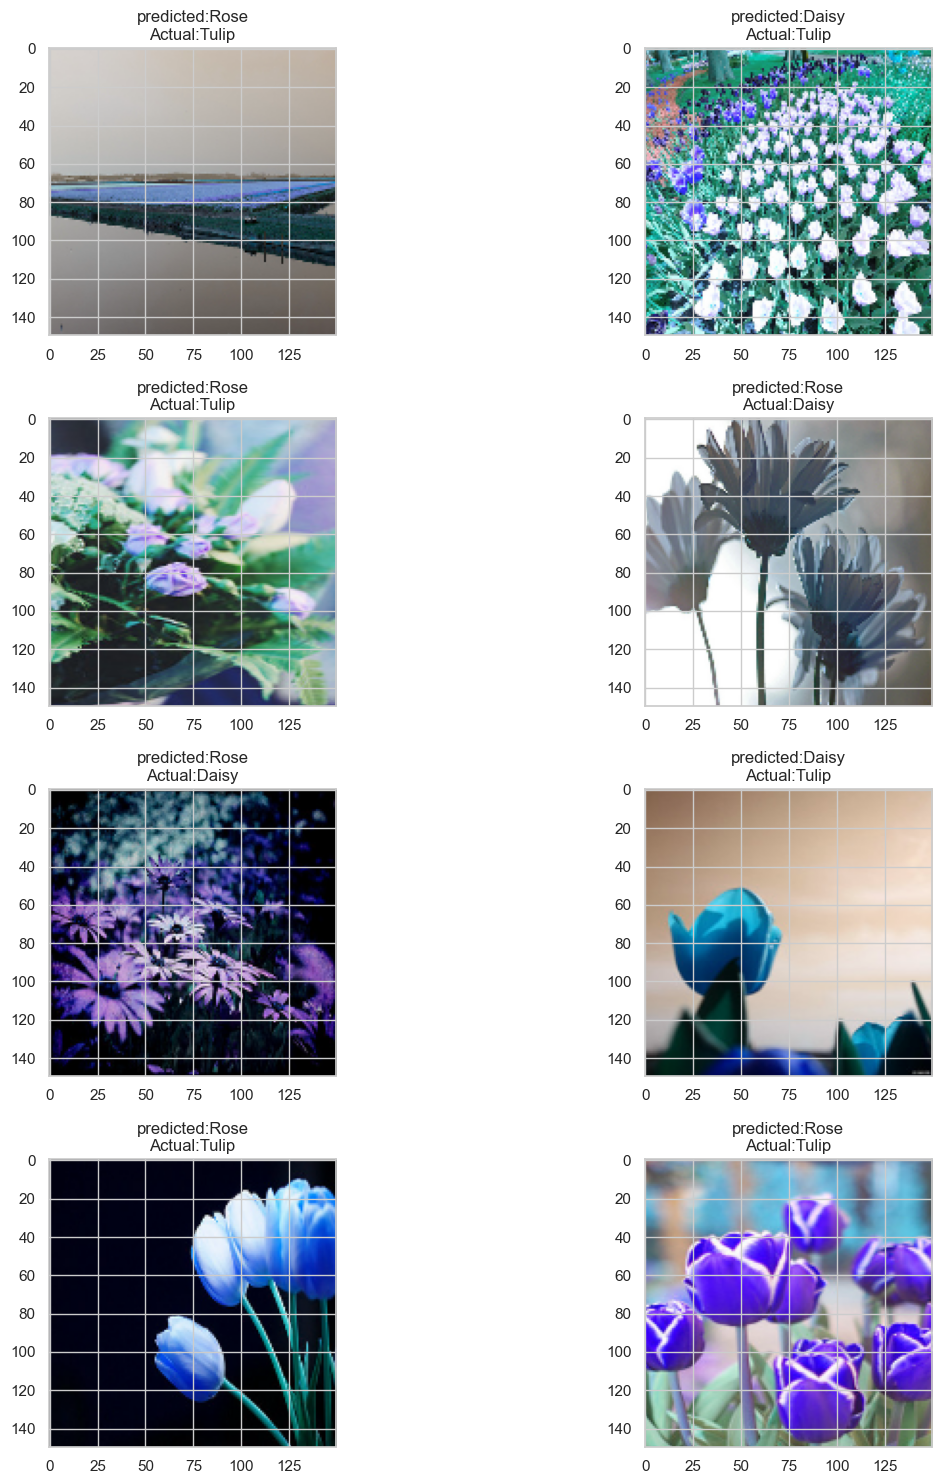

In [64]:
miss_classified_idx=np.where(pred_digits!=y_test.argmax(axis=1))[0]
print(f"total misclassified samples:{len(miss_classified_idx)}")
rows,cols=4,2
fig,ax=plt.subplots(rows,cols,figsize=(15,15))
count=0
for i in range(rows):
    for j in range(cols):
        if count<len(miss_classified_idx):
            idx=miss_classified_idx[count]
            pred_label=le.inverse_transform([pred_digits[idx]])[0]
            actual_label=le.inverse_transform([y_test[idx].argmax()])[0]
            ax[i,j].imshow(x_test[idx])
            ax[i,j].set_title(f"predicted:{pred_label}\nActual:{actual_label}")
            count+=1
        else:
            ax[i,j].axis("Off")
plt.tight_layout()
plt.show()